# 05 · Respostas às perguntas de negócio

Todas as respostas são consultas SQL sobre a gold. Cada pergunta tem uma célula de consulta e tabela e outra de gráfico. Os gráficos também são gravados no volume `olist_gold.graficos` e reproduzidos no README. A interpretação dos números está no README, seção 6.

Universo padrão: pedidos entregues (RN01). Nas análises de etapas do lead time saem os pedidos com inconsistência temporal (RN07); nas de rota e vendedor, só entram pedidos de vendedor único (RN14, RN15, RN17).

In [ ]:
import json
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

dbutils.widgets.text("catalogo", "workspace", "Catálogo do Unity Catalog")
CATALOGO = dbutils.widgets.get("catalogo")
spark.sql(f"USE {CATALOGO}.olist_gold")
spark.sql(f"CREATE VOLUME IF NOT EXISTS {CATALOGO}.olist_gold.graficos")
GRAFICOS = f"/Volumes/{CATALOGO}/olist_gold/graficos"
q = lambda sql: spark.sql(sql).toPandas()
resumo = {}

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.titlesize": 10.5, "axes.titleweight": "bold", "font.size": 9})
AZUL, CINZA, LARANJA = "#1f5f99", "#9aa5b1", "#d9822b"
br = lambda x, casas=1: f"{x:,.{casas}f}".replace(",", "X").replace(".", ",").replace("X", ".")
eixo_br = FuncFormatter(lambda v, _: br(v, 0) if float(v).is_integer() else br(v, 1))

def fechar(nome):
    plt.tight_layout()
    plt.savefig(f"{GRAFICOS}/{nome}.png", dpi=150, bbox_inches="tight")
    plt.show()

## P1 · Nível de serviço
Qual a proporção de pedidos entregues depois da data prometida, como ela evoluiu mês a mês entre janeiro de 2017 e agosto de 2018 e em quais meses houve picos?

In [ ]:
global_ = q("""SELECT count(*) AS pedidos_entregues, sum(int(flag_atrasado)) AS atrasados,
                      round(avg(int(flag_atrasado)), 4) AS taxa_atraso
               FROM fato_pedido WHERE flag_entregue""")
mensal = q("""SELECT d.ano_mes, count(*) AS pedidos, sum(int(f.flag_atrasado)) AS atrasados,
                     round(avg(int(f.flag_atrasado)), 4) AS taxa_atraso,
                     round(avg(f.dias_prometidos), 1) AS prazo_prometido_medio
              FROM fato_pedido f JOIN dim_data d ON d.data_key = f.data_compra_key
              WHERE f.flag_entregue AND d.ano_mes BETWEEN '2017-01' AND '2018-08'
              GROUP BY d.ano_mes ORDER BY d.ano_mes""")
resumo["p1"] = {"global": global_.iloc[0].to_dict(), "serie": mensal.to_dict("records")}
print(f"Taxa global de atraso: {global_.taxa_atraso[0]:.2%} ({int(global_.atrasados[0])} de {int(global_.pedidos_entregues[0])} pedidos entregues)")
display(mensal)

Taxa global de atraso: 6.77% (6534 de 96470 pedidos entregues)


ano_mes,pedidos,atrasados,taxa_atraso,prazo_prometido_medio
2017-01,750,22,0.0293,40.2
2017-02,1653,49,0.0296,32.5
2017-03,2546,116,0.0456,25.4
2017-04,2303,151,0.0656,28.0
2017-05,3545,106,0.0299,24.9
2017-06,3135,95,0.0303,24.7
2017-07,3872,108,0.0279,24.0
2017-08,4193,122,0.0291,24.1
2017-09,4150,182,0.0439,23.1
2017-10,4478,187,0.0418,23.7


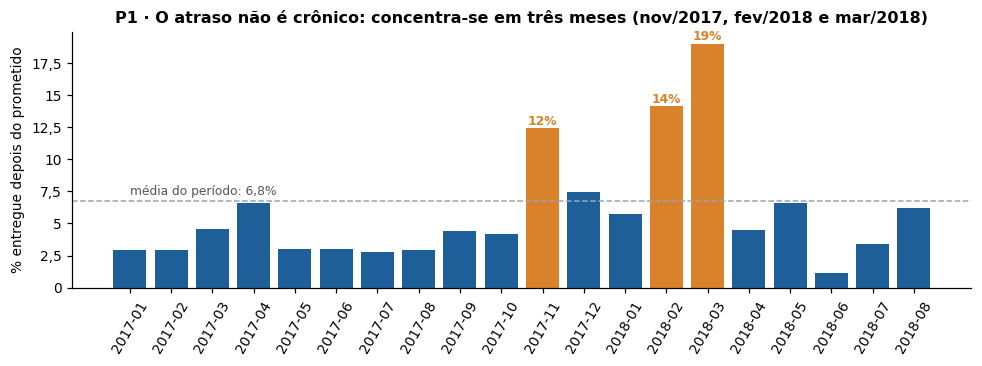

In [ ]:
fig, ax = plt.subplots(figsize=(9, 3.4))
ax.bar(mensal.ano_mes, mensal.taxa_atraso * 100, color=[LARANJA if t > 0.10 else AZUL for t in mensal.taxa_atraso])
media = global_.taxa_atraso[0] * 100
ax.axhline(media, color=CINZA, ls="--", lw=1)
ax.text(0, media + 0.5, f"média do período: {br(media)}%", color="#555", fontsize=8)
for x, t in zip(mensal.ano_mes, mensal.taxa_atraso):
    if t > 0.10: ax.text(x, t * 100 + 0.3, f"{t:.0%}", ha="center", fontsize=8, color=LARANJA, fontweight="bold")
ax.set_ylabel("% entregue depois do prometido"); ax.yaxis.set_major_formatter(eixo_br)
ax.set_title("P1 · O atraso não é crônico: concentra-se em três meses (nov/2017, fev/2018 e mar/2018)")
ax.tick_params(axis="x", rotation=60)
fechar("p1_taxa_atraso_mensal")

## P2 · Origem do atraso
Nos pedidos atrasados, o atraso nasce na postagem do vendedor ou no transporte? Qual etapa do lead time mais se alonga nos pedidos atrasados?

In [ ]:
origem = q("""SELECT origem_atraso, count(*) AS pedidos,
                     round(count(*) / sum(count(*)) OVER (), 4) AS participacao
              FROM fato_pedido
              WHERE flag_entregue AND flag_atrasado AND NOT flag_inconsistencia_temporal AND origem_atraso IS NOT NULL
              GROUP BY origem_atraso ORDER BY pedidos DESC""")
etapas = q("""SELECT CASE WHEN flag_atrasado THEN 'atrasado' ELSE 'no prazo' END AS grupo, count(*) AS pedidos,
                     round(median(dias_aprovacao), 2) AS aprovacao, round(median(dias_postagem), 2) AS postagem,
                     round(median(dias_transporte), 2) AS transporte, round(median(dias_lead_time), 2) AS lead_time,
                     round(median(dias_prometidos), 1) AS prometido,
                     round(avg(int(flag_postagem_tardia)), 4) AS taxa_postagem_tardia
              FROM fato_pedido WHERE flag_entregue AND NOT flag_inconsistencia_temporal
              GROUP BY 1 ORDER BY 1""")
resumo["p2"] = {"origem": origem.to_dict("records"), "etapas_medianas": etapas.to_dict("records")}
display(origem)

origem_atraso,pedidos,participacao
transporte,4695,0.7213
vendedor,1814,0.2787


In [ ]:
display(etapas)

grupo,pedidos,aprovacao,postagem,transporte,lead_time,prometido,taxa_postagem_tardia
atrasado,6510,0.02,3.07,26.2,31.26,23.0,0.2787
no prazo,88587,0.01,1.79,6.96,9.86,24.0,0.0777


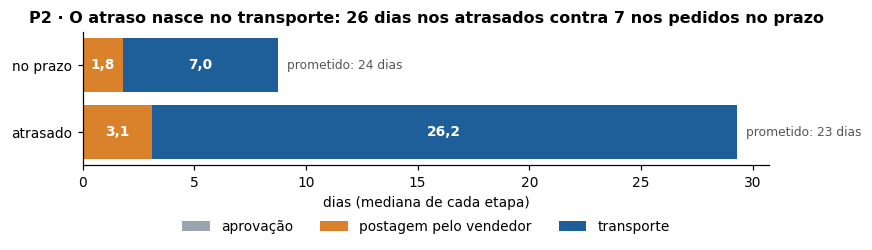

In [ ]:
fig, ax = plt.subplots(figsize=(8, 2.6))
for i, g in enumerate(etapas.itertuples()):
    esquerda = 0
    for etapa, rotulo, cor in [("aprovacao", "aprovação", CINZA), ("postagem", "postagem pelo vendedor", LARANJA), ("transporte", "transporte", AZUL)]:
        v = getattr(g, etapa)
        ax.barh(g.grupo, v, left=esquerda, color=cor, label=rotulo if i == 0 else None)
        if v > 1: ax.text(esquerda + v / 2, i, br(v), va="center", ha="center", color="white", fontweight="bold")
        esquerda += v
    ax.text(esquerda + 0.4, i, f"prometido: {g.prometido:.0f} dias", va="center", fontsize=8, color="#555")
ax.set_xlabel("dias (mediana de cada etapa)")
ax.legend(frameon=False, ncol=3, loc="upper center", bbox_to_anchor=(0.5, -0.32))
ax.set_title("P2 · O atraso nasce no transporte: 26 dias nos atrasados contra 7 nos pedidos no prazo")
fechar("p2_etapas_lead_time")

## P3 · Concentração geográfica
Quais rotas (UF do vendedor para UF do cliente, com pelo menos 300 pedidos) têm maior taxa de atraso e quanto do total de atrasos elas concentram? Como a distância se relaciona com o atraso?

In [ ]:
rotas = q("""WITH base AS (
               SELECT concat(v.uf, '->', c.uf) AS rota, f.flag_atrasado
               FROM fato_pedido f JOIN dim_vendedor v USING (seller_id) JOIN dim_cliente c USING (customer_id)
               WHERE f.flag_entregue)
             SELECT rota, count(*) AS pedidos, sum(int(flag_atrasado)) AS atrasados,
                    round(avg(int(flag_atrasado)), 4) AS taxa_atraso,
                    round(sum(int(flag_atrasado)) / (SELECT sum(int(flag_atrasado)) FROM base), 4) AS participacao_atrasos
             FROM base GROUP BY rota HAVING count(*) >= 300 ORDER BY taxa_atraso DESC""")
top10 = rotas.head(10)
resumo["p3"] = {"rotas_elegiveis": len(rotas), "top10": top10.to_dict("records"),
                "participacao_top10": round(float(top10.participacao_atrasos.sum()), 4)}
print(f"{len(rotas)} rotas com pelo menos 300 pedidos; as dez piores concentram {top10.participacao_atrasos.sum():.1%} dos atrasos")
display(top10)

38 rotas com pelo menos 300 pedidos; as dez piores concentram 33.7% dos atrasos


rota,pedidos,atrasados,taxa_atraso,participacao_atrasos
SP->MA,486,93,0.1914,0.0143
SP->PI,327,54,0.1651,0.0083
SP->RJ,8048,1147,0.1425,0.1759
SP->CE,961,133,0.1384,0.0204
SP->BA,2278,297,0.1304,0.0455
SP->MS,471,59,0.1253,0.009
SP->ES,1444,180,0.1247,0.0276
PR->RJ,951,117,0.123,0.0179
SP->PA,675,81,0.12,0.0124
SP->PB,333,35,0.1051,0.0054


In [ ]:
distancia = q("""SELECT CASE WHEN distancia_km < 100 THEN '1. até 100 km' WHEN distancia_km < 500 THEN '2. 100 a 500 km'
                             WHEN distancia_km < 1000 THEN '3. 500 a 1.000 km' WHEN distancia_km < 2000 THEN '4. 1.000 a 2.000 km'
                             ELSE '5. 2.000 km ou mais' END AS faixa_distancia,
                        count(*) AS pedidos, round(avg(int(flag_atrasado)), 4) AS taxa_atraso,
                        round(median(dias_transporte), 1) AS transporte_mediano, round(median(dias_prometidos), 1) AS prometido_mediano
                 FROM fato_pedido WHERE flag_entregue AND distancia_km IS NOT NULL
                 GROUP BY 1 ORDER BY 1""")
resumo["p3"]["distancia"] = distancia.to_dict("records")
display(distancia)

faixa_distancia,pedidos,taxa_atraso,transporte_mediano,prometido_mediano
1. até 100 km,17694,0.045,2.1,15.0
2. 100 a 500 km,36462,0.0618,6.5,23.0
3. 500 a 1.000 km,25389,0.0721,8.8,26.0
4. 1.000 a 2.000 km,9608,0.0961,12.3,30.0
5. 2.000 km ou mais,5571,0.1208,14.8,34.0


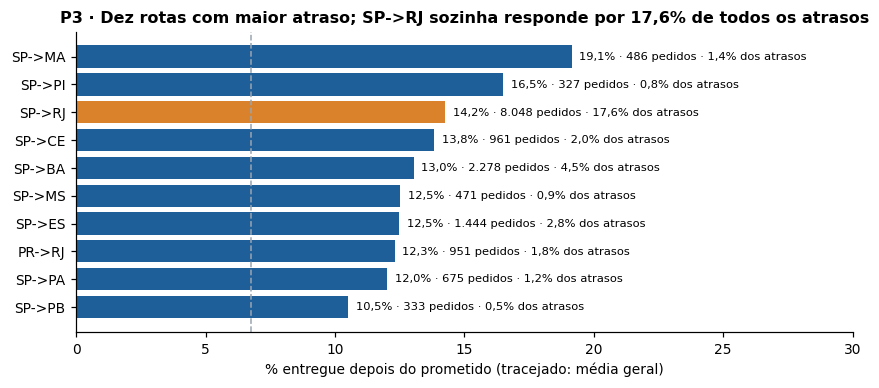

In [ ]:
fig, ax = plt.subplots(figsize=(8, 3.6))
ax.barh(top10.rota[::-1], top10.taxa_atraso[::-1] * 100, color=[LARANJA if r == "SP->RJ" else AZUL for r in top10.rota[::-1]])
for y, (t, n, p) in enumerate(zip(top10.taxa_atraso[::-1], top10.pedidos[::-1], top10.participacao_atrasos[::-1])):
    ax.text(t * 100 + 0.3, y, f"{br(t * 100)}% · {br(n, 0)} pedidos · {br(p * 100)}% dos atrasos", va="center", fontsize=7.5)
ax.axvline(global_.taxa_atraso[0] * 100, color=CINZA, ls="--", lw=1)
ax.set_xlim(0, 30); ax.set_xlabel("% entregue depois do prometido (tracejado: média geral)")
ax.set_title("P3 · Dez rotas com maior atraso; SP->RJ sozinha responde por 17,6% de todos os atrasos")
fechar("p3_rotas_criticas")

## P4 · Calibração da promessa
O prazo prometido está calibrado por UF de destino? Em quais UFs a promessa é folgada demais e em quais ela é violada com frequência?

In [ ]:
calibracao = q("""SELECT c.uf, c.regiao, count(*) AS pedidos,
                         round(median(f.dias_prometidos), 1) AS prazo_prometido_mediano,
                         round(median(f.dias_lead_time), 1) AS lead_time_mediano,
                         round(median(f.folga_dias), 1) AS folga_mediana,
                         round(avg(int(f.flag_atrasado)), 4) AS taxa_atraso
                  FROM fato_pedido f JOIN dim_cliente c USING (customer_id)
                  WHERE f.flag_entregue GROUP BY c.uf, c.regiao ORDER BY folga_mediana DESC""")
resumo["p4"] = calibracao.to_dict("records")
display(calibracao)

uf,regiao,pedidos,prazo_prometido_mediano,lead_time_mediano,folga_mediana,taxa_atraso
AC,Norte,80,41.0,18.4,22.0,0.0375
AP,Norte,67,48.0,24.3,22.0,0.0299
RO,Norte,243,38.0,17.6,21.0,0.0288
RR,Norte,41,45.0,25.0,20.0,0.122
AM,Norte,145,46.0,25.9,19.0,0.0276
PA,Norte,946,37.0,21.1,16.0,0.1121
RS,Sul,5344,29.0,13.2,15.0,0.0608
RN,Nordeste,474,32.5,16.1,15.0,0.0928
MT,Centro-Oeste,886,32.0,16.1,15.0,0.0598
PB,Nordeste,517,33.0,18.2,14.0,0.1044


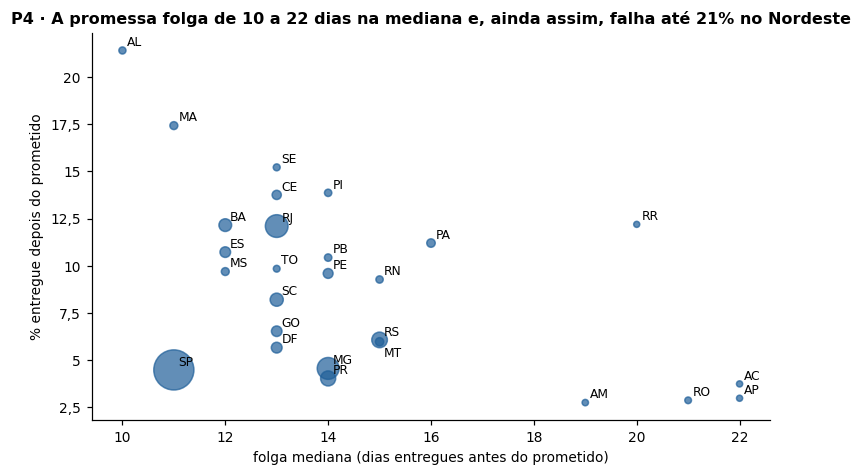

In [ ]:
fig, ax = plt.subplots(figsize=(7, 4.4))
ax.scatter(calibracao.folga_mediana, calibracao.taxa_atraso * 100, s=calibracao.pedidos / 60 + 15, color=AZUL, alpha=.7)
for r in calibracao.itertuples():
    deslocamento = (3, -10) if r.uf == "MT" else (3, 3)
    ax.annotate(r.uf, (r.folga_mediana, r.taxa_atraso * 100), fontsize=8, xytext=deslocamento, textcoords="offset points")
ax.yaxis.set_major_formatter(eixo_br)
ax.set_xlabel("folga mediana (dias entregues antes do prometido)"); ax.set_ylabel("% entregue depois do prometido")
ax.set_title("P4 · A promessa folga de 10 a 22 dias na mediana e, ainda assim, falha até 21% no Nordeste")
fechar("p4_calibracao_promessa")

## P5 · Impacto no cliente
Quanto a nota média e a proporção de avaliações ruins (1 ou 2) pioram por faixa de dias de atraso?

In [ ]:
avaliacao = q("""SELECT faixa_atraso, count(*) AS pedidos_com_avaliacao, round(avg(nota_avaliacao), 2) AS nota_media,
                        round(avg(int(flag_avaliacao_ruim)), 4) AS taxa_avaliacao_ruim
                 FROM fato_pedido WHERE flag_entregue AND nota_avaliacao IS NOT NULL
                 GROUP BY faixa_atraso
                 ORDER BY CASE faixa_atraso WHEN 'no prazo ou antecipado' THEN 0 WHEN '1 a 3 dias' THEN 1
                          WHEN '4 a 7 dias' THEN 2 WHEN '8 a 14 dias' THEN 3 ELSE 4 END""")
resumo["p5"] = avaliacao.to_dict("records")
display(avaliacao)

faixa_atraso,pedidos_com_avaliacao,nota_media,taxa_avaliacao_ruim
no prazo ou antecipado,89443,4.29,0.0927
1 a 3 dias,1852,3.29,0.3213
4 a 7 dias,1748,2.1,0.6768
8 a 14 dias,1446,1.67,0.8015
15 dias ou mais,1335,1.72,0.7835


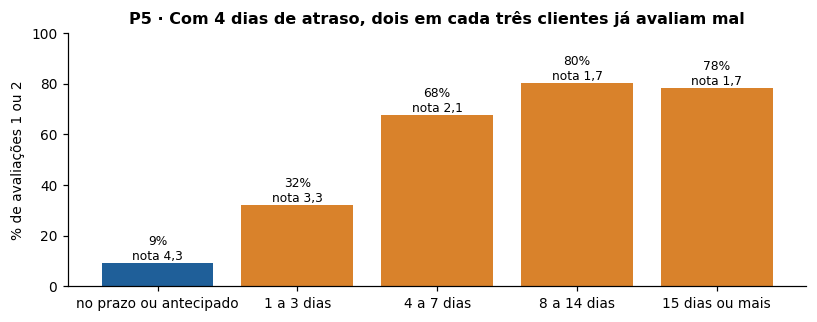

In [ ]:
fig, ax = plt.subplots(figsize=(7.5, 3))
barras = ax.bar(avaliacao.faixa_atraso, avaliacao.taxa_avaliacao_ruim * 100,
                color=[AZUL] + [LARANJA] * (len(avaliacao) - 1))
ax.bar_label(barras, labels=[f"{t:.0%}\nnota {br(n)}" for t, n in zip(avaliacao.taxa_avaliacao_ruim, avaliacao.nota_media)], fontsize=8)
ax.set_ylabel("% de avaliações 1 ou 2"); ax.set_ylim(0, 100)
ax.set_title("P5 · Com 4 dias de atraso, dois em cada três clientes já avaliam mal")
fechar("p5_avaliacao_por_atraso")

## P6 · Concentração nos vendedores
Entre vendedores com pelo menos 30 pedidos entregues, qual fração deles responde por 80% das postagens tardias?

In [ ]:
vendedores = q("""SELECT seller_id, count(*) AS pedidos, sum(int(flag_postagem_tardia)) AS postagens_tardias,
                         round(avg(int(flag_postagem_tardia)), 4) AS taxa_postagem_tardia,
                         round(avg(int(flag_atrasado)), 4) AS taxa_atraso
                  FROM fato_pedido WHERE flag_entregue AND seller_id IS NOT NULL
                  GROUP BY seller_id HAVING count(*) >= 30
                  ORDER BY postagens_tardias DESC, pedidos DESC""")
vendedores["acumulado"] = vendedores.postagens_tardias.cumsum() / vendedores.postagens_tardias.sum()
n80 = int((vendedores.acumulado < 0.8).sum()) + 1
resumo["p6"] = {"vendedores_elegiveis": len(vendedores), "postagens_tardias": int(vendedores.postagens_tardias.sum()),
                "vendedores_para_80pct": n80, "fracao_vendedores_80pct": round(n80 / len(vendedores), 4),
                "top10": vendedores.head(10).drop(columns="acumulado").to_dict("records")}
print(f"{n80} de {len(vendedores)} vendedores ({n80 / len(vendedores):.1%}) respondem por 80% das postagens tardias")
display(vendedores.head(10).drop(columns="acumulado"))

162 de 615 vendedores (26.3%) respondem por 80% das postagens tardias


seller_id,pedidos,postagens_tardias,taxa_postagem_tardia,taxa_atraso
7c67e1448b00f6e969d365cea6b010ab,963,288,0.2991,0.0924
1025f0e2d44d7041d6cf58b6550e0bfa,879,161,0.1832,0.0819
4a3ca9315b744ce9f8e9374361493884,1673,151,0.0903,0.1004
1f50f920176fa81dab994f9023523100,1364,149,0.1092,0.0909
3d871de0142ce09b7081e2b9d1733cb1,1044,137,0.1312,0.0556
06a2c3af7b3aee5d69171b0e14f0ee87,388,121,0.3119,0.1907
88460e8ebdecbfecb5f9601833981930,227,116,0.511,0.185
53e4c6e0f4312d4d2107a8c9cddf45cd,444,94,0.2117,0.0495
8160255418d5aaa7dbdc9f4c64ebda44,355,90,0.2535,0.1437
ea8482cd71df3c1969d7b9473ff13abc,1116,87,0.078,0.086


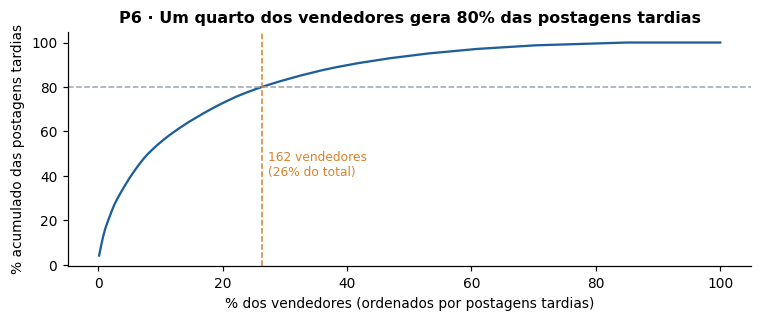

In [ ]:
fig, ax = plt.subplots(figsize=(7, 3))
x = (vendedores.index + 1) / len(vendedores) * 100
ax.plot(x, vendedores.acumulado * 100, color=AZUL)
ax.axhline(80, color=CINZA, ls="--", lw=1); ax.axvline(n80 / len(vendedores) * 100, color=LARANJA, ls="--", lw=1)
ax.text(n80 / len(vendedores) * 100 + 1, 40, f"{n80} vendedores\n({n80 / len(vendedores):.0%} do total)", color=LARANJA, fontsize=8)
ax.set_xlabel("% dos vendedores (ordenados por postagens tardias)"); ax.set_ylabel("% acumulado das postagens tardias")
ax.set_title("P6 · Um quarto dos vendedores gera 80% das postagens tardias")
fechar("p6_pareto_vendedores")

## Resumo para conciliação
O resumo é gravado no volume e comparado pelo script `scripts/conciliacao.py` com o resultado do script independente `scripts/validacao_referencia.py`, escrito em pandas sem reaproveitar este código.

In [ ]:
texto = json.dumps(resumo, ensure_ascii=False, default=str, indent=1)
with open(f"{GRAFICOS}/resultado_databricks.json", "w", encoding="utf-8") as f:
    f.write(texto)
print(f"Resumo gravado em {GRAFICOS}/resultado_databricks.json ({len(texto)} caracteres)")

Resumo gravado em /Volumes/workspace/olist_gold/graficos/resultado_databricks.json (13494 caracteres)
